In [ ]:
main_dir = '../'

In [ ]:
import matplotlib.pyplot as plt
from tqdm import tqdm
import pandas as pd
import xarray as xr
import numpy as np
import argparse
import logging
import sys
import os

sys.path.append(os.path.join(main_dir, 'library'))

from atmocean.forecast import *
from atmocean.models import *
from atmocean.macros import (
    ALL_DATA_VARS,
    MEAN_DATA_VARS,
    STD_DATA_VARS,
)
import warnings
warnings.filterwarnings('ignore')

/Users/davide/anaconda3/envs/fmlenv/lib/python3.11/site-packages/torch/cuda/__init__.py:58: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [ ]:
model_weights_src = os.path.join(main_dir, 'data/models/neptune-1/neptune.pt')
model_config_src = os.path.join(main_dir, 'data/models/neptune-1/configuration-pretrain.toml')
device = 'cuda' if torch.cuda.is_available() else 'cpu'
res = '1'
ensemble_size = 1
shape = (181, 360)
sealand_mask_3d_src = os.path.join(main_dir, f'data/masks/sealand_{res}_deg/sealand_mask_3d.npy')
sealand_mask_2d_src = os.path.join(main_dir, f'data/masks/sealand_{res}_deg/sealand_mask_2d.npy')
data_dir = os.path.join(main_dir, f'data/datasets/all_{res}_deg')
dtype = torch.float32
# get the sealand mask
sealand_mask_3d = np.load(sealand_mask_3d_src)
sealand_mask_2d = np.load(sealand_mask_2d_src)

In [3]:
def _fmt_num(n: int) -> str:
    """Format large numbers with K / M / B suffix."""
    if n >= 1_000_000_000:
        return f"{n / 1_000_000_000:.1f} B"
    if n >= 1_000_000:
        return f"{n / 1_000_000:.1f} M"
    if n >= 1_000:
        return f"{n / 1_000:.1f} K"
    return str(n)

def model_summary(model: nn.Module, max_depth: int = 2) -> str:
    """
    Print a model summary similar to Lightning's ModelSummary.

    Args:
        model    : the nn.Module to summarise.
        max_depth: how many levels of submodules to show (default 2).

    Returns:
        The summary string (also printed to stdout).
    """

    rows = []

    def _add_rows(module: nn.Module, prefix: str, depth: int):
        for name, child in module.named_children():
            full_name = f"{prefix}.{name}" if prefix else name
            if depth <= max_depth:
                n_params  = sum(p.numel() for p in child.parameters())
                trainable = sum(p.numel() for p in child.parameters() if p.requires_grad)
                rows.append((full_name, child.__class__.__name__, n_params, trainable))
                _add_rows(child, full_name, depth + 1)

    _add_rows(model, "", 1)

    # totals
    total_params     = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    non_trainable    = total_params - trainable_params

    # column widths
    col_name  = max((len(r[0]) for r in rows), default=10)
    col_type  = max((len(r[1]) for r in rows), default=10)
    col_name  = max(col_name, len("Name"))
    col_type  = max(col_type, len("Type"))
    col_par   = max(len("Params"), 10)

    sep   = f"{'─' * (col_name + col_type + col_par * 2 + 13)}"
    fmt   = f"{{:<{col_name}}}  {{:<{col_type}}}  {{:>{col_par}}}  {{:>{col_par}}}"
    lines = []

    lines.append(sep)
    lines.append(f"  Model: {model.__class__.__name__}")
    lines.append(sep)
    lines.append(fmt.format("Name", "Type", "Params", "Trainable"))
    lines.append(sep)

    for name, cls, n, t in rows:
        lines.append(fmt.format(name, cls, _fmt_num(n), _fmt_num(t)))

    lines.append(sep)
    lines.append(f"{'Total params':>{col_name + col_type + 4}}  {_fmt_num(total_params):>{col_par}}")
    lines.append(f"{'Trainable params':>{col_name + col_type + 4}}  {_fmt_num(trainable_params):>{col_par}}")
    lines.append(f"{'Non-trainable params':>{col_name + col_type + 4}}  {_fmt_num(non_trainable):>{col_par}}")
    lines.append(sep)

    summary = "\n".join(lines)
    print(summary)
    return summary

def load_model_from_config(
    model_weights_src,
    config_src,
    log_summary: bool = False,
    verbose: bool = False,
    device: str = 'cpu',
):
    # load config file
    cfg = munch.munchify(toml.load(config_src))

    # load the PyTorch model
    state_dict = torch.load(model_weights_src, weights_only=False, map_location=device)

    # clean the checkpoint state
    state_dict = clean_state_dict_checkpoint_wrapped_module_from_keys(state_dict)
    state_dict = clean_state_dict_forward_module_from_keys(state_dict)

    # log
    if verbose: print(f"State dict loaded from {model_weights_src}")

    # add arguments to core configuration
    model_args = {'drivers': ALL_DRIVERS, 'insteps': cfg.train.insteps, 'outsteps': cfg.train.outsteps, **dict(cfg.model.args)}

    # init model
    model:Neptune = eval(cfg.model.cls)(**model_args)

    if hasattr(cfg.train, 'is_residual'):
        is_residual = cfg.train.is_residual
    else:
        is_residual = False

    # add attributes to the model
    model.set_attributes(
        optimizer = None,
        scheduler = None,
        loss = None,
        metrics = None,
        insteps = cfg.train.insteps,
        outsteps = cfg.train.outsteps,
        lead_time = cfg.train.lead_time,
        rollout = 1,
        is_rollout = False,
        is_ens = True if 'ensemble_size' in model_args.keys() else False,
        is_residual = is_residual,
    )

    # load model weights
    mkeys, ukeys = model.load_state_dict(state_dict['state_dict'], strict=False)
    if (not "embedding.weights.noise" in mkeys and len(mkeys) != 0):
        raise RuntimeError(f"Error(s) in loading state_dict for {model.__class__.__name__}:\nMissing keys: {mkeys}\nUnexpected keys: {ukeys}")

    # log
    if verbose: print(f"Model initialized")

    # log
    if log_summary:
        # summary of the model structure
        model_summary(model, max_depth=2)

    # put the model to device
    model = model.to(device)

    # return
    return model, cfg, state_dict

def get_day_of_year(fname):
    '''Day and Month of the Year (DMoY)'''
    date = os.path.basename(fname).split('.npy')[0]
    date = pd.to_datetime(date)
    day_of_year = pd.Period(date, freq='d').day_of_year
    return day_of_year

def add_day_of_year(files):
    doy = torch.cat([
        torch.as_tensor([get_day_of_year(file)]) 
        for file in files
    ])
    return doy

def load_unpack(files, fill_value=0.0, epsilon=1e-7):
    tdim = 1
    # read all the timesteps and stack them
    data = torch.stack([torch.as_tensor(np.load(file, mmap_mode='c'), dtype=dtype) for file in files], dim=tdim)
    # get only the data belonging to the data vars
    batch = torch.stack([prepare_data(data[i], var, fill_value, epsilon) for i,var in enumerate(ALL_DATA_VARS)])
    return batch

def prepare_data(data, var, fill_value=0.0, epsilon=1e-7):
    # scale the data with its own scaler
    data = (data - MEAN_DATA_VARS[var]) / (STD_DATA_VARS[var] + epsilon)
    # remove nan values
    data = torch.nan_to_num(data, nan=fill_value)
    return data

In [4]:
# initialize the ML model
model, config, state_dict = load_model_from_config(
    model_weights_src=model_weights_src,
    config_src=model_config_src,
    log_summary=True,
    verbose=True,
    device=device,
)
model.ensemble_size = ensemble_size
# get information from the loaded configuration
insteps = config.train.insteps
outsteps = config.train.outsteps
lead_time = config.train.lead_time
drivers = config.data.drivers
fill_value = config.data.fill_value
epsilon = config.data.epsilon
# disable gradients for inference
torch.set_grad_enabled(False)

State dict loaded from data/models/neptune-1/neptune.pt
Using the custom implementation of load_state_dict()
State dict keys: dict_keys(['phy_to_latent.bias', 'phy_to_latent.weights.10m_u_component_of_wind', 'phy_to_latent.weights.10m_v_component_of_wind', 'phy_to_latent.weights.2m_dewpoint_temperature', 'phy_to_latent.weights.2m_temperature', 'phy_to_latent.weights.geopotential_1000', 'phy_to_latent.weights.geopotential_300', 'phy_to_latent.weights.geopotential_500', 'phy_to_latent.weights.geopotential_600', 'phy_to_latent.weights.geopotential_700', 'phy_to_latent.weights.geopotential_850', 'phy_to_latent.weights.geopotential_925', 'phy_to_latent.weights.mean_sea_level_pressure', 'phy_to_latent.weights.mlotst_oras', 'phy_to_latent.weights.noise', 'phy_to_latent.weights.sea_ice_cover', 'phy_to_latent.weights.sea_surface_temperature', 'phy_to_latent.weights.siconc_oras', 'phy_to_latent.weights.sithick_oras', 'phy_to_latent.weights.so_oras_0', 'phy_to_latent.weights.so_oras_1', 'phy_to_l

In [5]:
# two input files
files = [
    'data/datasets/all_1_deg/20200410.npy',
    'data/datasets/all_1_deg/20200411.npy',
]

# read all the timesteps and stack them
data = torch.stack([torch.as_tensor(np.load(file, mmap_mode='c'), dtype=dtype) for file in files], dim=1)

# get only the data belonging to the data vars
x = torch.stack([prepare_data(data[i], var, fill_value, epsilon) for i,var in enumerate(ALL_DATA_VARS)])

# day of year
t = add_day_of_year(files)

# add batch dimension
x = x.unsqueeze(0)
t = t.unsqueeze(0)

# move to device
x = x.to(device)
t = t.to(device)

# create noise conditioning
D = model.dim # latent dimension
B, _, _, H, W = x.shape
c = torch.randn((B, D, insteps, H, W), dtype=dtype, device=device)

x.shape, c.shape, t.shape

(torch.Size([1, 110, 2, 181, 360]),
 torch.Size([1, 256, 2, 181, 360]),
 torch.Size([1, 2]))

In [6]:
tdim = 2
# deaggregate variables into atmosphere-ocean components
xa3d, xa2d, xo3d, xo2d = deaggregate_systems(
    x,
    drivers['input']['atmos']['fields_3d'],
    drivers['input']['atmos']['fields_2d'],
    drivers['input']['ocean']['fields_3d'],
    drivers['input']['ocean']['fields_2d'],
)
(
    xa3d.shape if xa3d is not None else None,
    xa2d.shape if xa2d is not None else None,
    xo3d.shape if xo3d is not None else None,
    xo2d.shape if xo2d is not None else None,
)

(None,
 torch.Size([1, 5, 2, 1, 181, 360]),
 torch.Size([1, 4, 2, 14, 181, 360]),
 torch.Size([1, 4, 2, 1, 181, 360]))

In [7]:
preds = model(
    x=(xa3d,xa2d,xo3d,xo2d), # input data
    t=t,                     # day of year
    c=None,                  # noise (if None, the network will create it)
    drivers=drivers,         # I/O drivers
)
# get each component
dya3d, dya2d, dyo3d, dyo2d = preds

# since Neptune predicts only the ocean, we will
# only have dyo3d and dyo2d
(
    dya3d.shape if dya3d is not None else None,
    dya2d.shape if dya2d is not None else None,
    dyo3d.shape if dyo3d is not None else None,
    dyo2d.shape if dyo2d is not None else None,
)

(None,
 None,
 torch.Size([1, 4, 2, 14, 181, 360]),
 torch.Size([1, 4, 2, 1, 181, 360]))

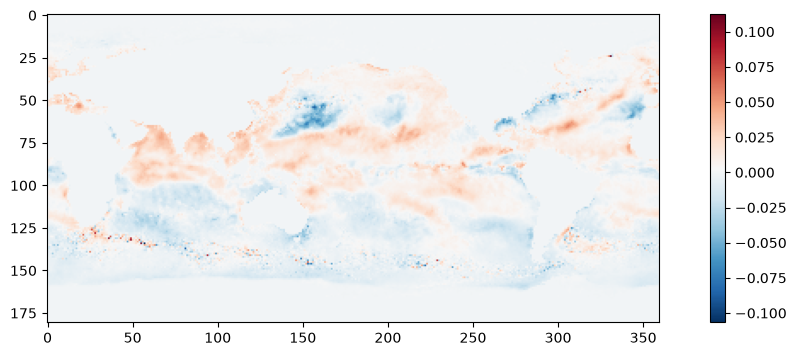

In [8]:
plt.figure(figsize=(13,4))
plt.imshow(dyo3d[0,0,0,0].cpu().numpy(), cmap='RdBu_r')
plt.colorbar()
plt.show()

In [9]:
# sum the input ocean to get the actual field
ya3d = xa3d + dya3d if dya3d is not None else None
ya2d = xa2d + dya2d if dya2d is not None else None
yo3d = xo3d + dyo3d if dyo3d is not None else None
yo2d = xo2d + dyo2d if dyo2d is not None else None
(
    ya3d.shape if ya3d is not None else None,
    ya2d.shape if ya2d is not None else None,
    yo3d.shape if yo3d is not None else None,
    yo2d.shape if yo2d is not None else None,
)

(None,
 None,
 torch.Size([1, 4, 2, 14, 181, 360]),
 torch.Size([1, 4, 2, 1, 181, 360]))

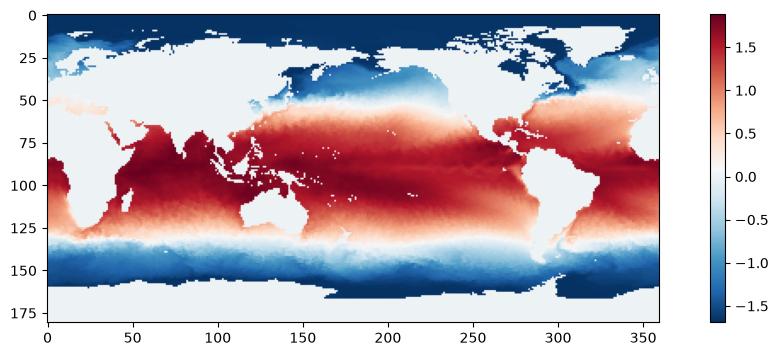

In [10]:
plt.figure(figsize=(13,4))
plt.imshow(yo3d[0,0,0,0].cpu().numpy(), cmap='RdBu_r')
plt.colorbar()
plt.show()

In [11]:
def rescale(x, drivers: dict, epsilon: float):
    a3d, a2d, o3d, o2d = x # B x V x T x Z x H x W
    af3d, af2d, of3d, of2d = (drivers['output']['atmos']['fields_3d'], 
                              drivers['output']['atmos']['fields_2d'], 
                              drivers['output']['ocean']['fields_3d'], 
                              drivers['output']['ocean']['fields_2d'])
    for i,field in enumerate(af3d):
        if a3d is not None:
            for l,level in enumerate(drivers['levels']):
                a3d[:,i,:,l] = unnormalize(a3d[:,i,:,l], f'{field}_{level}', epsilon)
    for i,field in enumerate(af2d):
        if a2d is not None:
            a2d[:,i,:] = unnormalize(a2d[:,i,:], field, epsilon)
    for i,field in enumerate(of3d):
            if o3d is not None:
                for d,depth in enumerate(drivers['depths']):
                    o3d[:,i,:,d] = unnormalize(o3d[:,i,:,d], f'{field}_{int(depth)}', epsilon)
    for i,field in enumerate(of2d):
        if o2d is not None:
            o2d[:,i,:] = unnormalize(o2d[:,i,:], field, epsilon)
    return (a3d, a2d, o3d, o2d)

In [12]:
# rescale the data to their physical value
ya3d_, ya2d_, yo3d_, yo2d_ = rescale((ya3d, ya2d, yo3d, yo2d), drivers, epsilon)

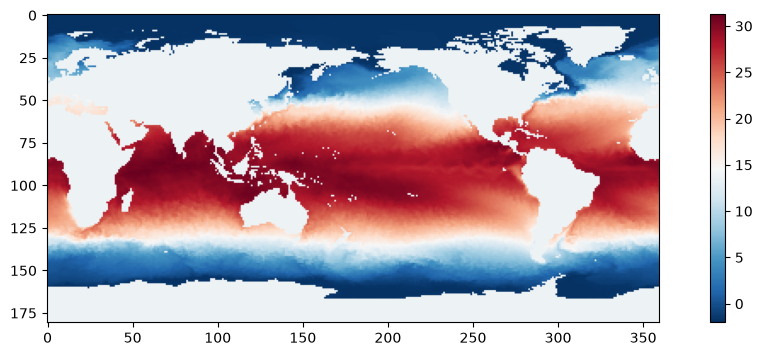

In [13]:
plt.figure(figsize=(13,4))
plt.imshow(yo3d_[0,0,0,0].cpu().numpy(), cmap='RdBu_r')
plt.colorbar()
plt.show()

In [14]:
y = yo3d_[0,0,0].cpu().numpy()
y[~sealand_mask_3d] = np.nan
y.shape

(14, 181, 360)

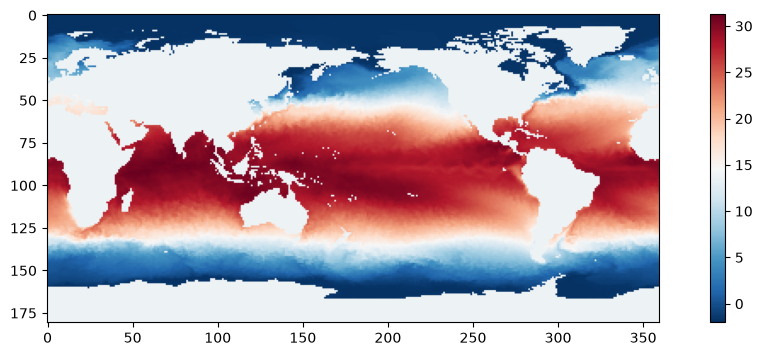

In [15]:
plt.figure(figsize=(13,4))
plt.imshow(y[0], cmap='RdBu_r')
plt.colorbar()
plt.show()

In [16]:
def apply_sealand_mask(data, mask):
    b, d, t, z, h, w = data.shape # data must have this shape
    # reshape the data to remove some dimensions
    data = rearrange(data, 'b d t z h w -> (b t d) z h w')
    # adapt the mask to the data
    new_mask = torch.as_tensor(mask.astype(bool)).unsqueeze(0)
    # broadcast the shapes
    new_mask = torch.broadcast_to(new_mask, size=data.shape)
    # apply the mask
    data[~mask] = torch.nan
    # rearrange the data to the previous shape
    data = rearrange(data, '(b t d) z h w -> b d t z h w', b=b, t=t, d=d)
    return data

In [17]:
# apply the sealand mask to remove data on the land
masked = apply_sealand_mask(yo3d_.cpu(), sealand_mask_3d)
masked.shape

torch.Size([1, 4, 2, 14, 181, 360])

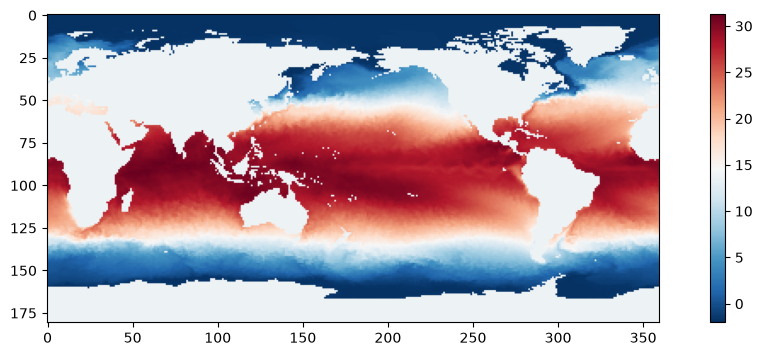

In [18]:
plt.figure(figsize=(13,4))
plt.imshow(masked[0,0,0,0].cpu().numpy(), cmap='RdBu_r')
plt.colorbar()
plt.show()